# Boosted trees: the shared 29-feature early-warning task

Mirrors `train_transformer.ipynb` and `train_random_forest.ipynb`, with reusable code in `src/boosted_trees/`.

- **Target:** measured speed **<40 mph at any of the next six five-minute readings** (the next 30 minutes), excluding the current reading.
- **Validation:** six quarterly walk-forward folds, 2024 Q1–2025 Q2, with the shared seven-day gap.
- **Inputs:** all **29 features in `sf.SHARED_FEATURES`**. The shared module is unchanged.
- **Training and scoring:** a new `HistGradientBoostingClassifier` per fold, trained on rows with measured future outcomes, predicting every
  validation row, scored with the shared functions. AP onsets is row-level AP on currently uncongested, measured stations.
- **Holdout:** July–December 2025 is never loaded or scored.

Start with `QUICK_RUN = True` (last fold only, never published to the team table). Set `False` to run all six folds, save each fold's
`validation_predictions.parquet` and a `manifest.json` under `src/boosted_trees/results/`, and update `notebooks/results/`.
The model settings are fixed in advance (300 trees, no early stopping), so no validation-selected checkpoint or hyperparameter search
happens here.

## Imports

In [1]:
from pathlib import Path
import sys

PROJECT_DIR = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "notebooks" / "safeflow_features.py").exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start the kernel in the SafeFlow project or one of its subfolders")
sys.path.insert(0, str(PROJECT_DIR))
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve
from IPython.display import display

import safeflow_features as sf
from src.boosted_trees import boosted_trees_training as training

LOCAL_DIR = PROJECT_DIR / "src" / "boosted_trees"
TEAM_RESULTS = PROJECT_DIR / "notebooks" / "results"
pd.set_option("display.width", 160)

## Settings

In [2]:
MODEL_NAME = "boosted_trees"
QUICK_RUN = False                 # True: 2025 Q2 only, not published. False: all six shared folds
TRAIN_SAMPLE = 2_000_000          # None for all eligible training rows
SAMPLE_SEED = 0                   # Same sampling convention as the other models
MODEL_SEED = 0
SAVE_MODELS = True                # Fitted models stay local (git-ignored)
MODEL_PARAMETERS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                        early_stopping=False, random_state=MODEL_SEED)

DATA_DIR = PROJECT_DIR / "Data"
if not (DATA_DIR / sf.META_FILE_NAME).exists():
    raise FileNotFoundError(f"Set DATA_DIR to the folder holding 'D12 2023', 'D12 2024', 'D12 2025' and {sf.META_FILE_NAME}")

RUN_NAME = f"{MODEL_NAME}_29_features_{'quick' if QUICK_RUN else 'full'}_{datetime.now():%Y%m%d_%H%M%S}"
RUN_DIR = LOCAL_DIR / "results" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)

print("Run mode:", "LAST FOLD ONLY" if QUICK_RUN else "ALL SIX FOLDS")
print("Outputs:", RUN_DIR.relative_to(PROJECT_DIR))
print("Model parameters:", MODEL_PARAMETERS)

Run mode: ALL SIX FOLDS
Outputs: src/boosted_trees/results/boosted_trees_29_features_full_20261104_000723
Model parameters: {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'early_stopping': False, 'random_state': 0}


## 1. Load data and define the feature list

The manifest records everything needed to check this run against the other models: features, code hashes, data hashes, settings,
seeds and fold definitions. It is rewritten after every fold, so an interrupted run still says which folds finished.

In [3]:
df = sf.build_dataset(DATA_DIR)
FEATURES = list(sf.SHARED_FEATURES)

assert len(FEATURES) == 29 and len(set(FEATURES)) == 29, "The shared feature set changed. Review it before rerunning"
assert not set(FEATURES).intersection(sf.FUTURE_COLUMNS)
assert not df.duplicated(sf.KEY).any()
assert df["timestamp"].max() < pd.Timestamp(sf.HOLDOUT_START)

folds = list(sf.folds(df, only_last=QUICK_RUN))
manifest = dict(
    model=MODEL_NAME, status="running", quick_run=QUICK_RUN, run_dir=RUN_NAME,
    features=FEATURES, feature_sha256=training.feature_hash(FEATURES),
    shared_code_sha256=training.sha256_file(sf.__file__),
    training_code_sha256=training.sha256_file(training.__file__),
    model_class="sklearn.ensemble.HistGradientBoostingClassifier",
    model_parameters=training.make_model(**MODEL_PARAMETERS).get_params(), model_factory_source=training.factory_source(),
    model_seed=MODEL_SEED, train_sample=TRAIN_SAMPLE, sample_seed=SAMPLE_SEED,
    sample_method="pandas sample(train_sample, random_state=sample_seed) over training rows with y_known, order kept",
    train_start=str(sf.TRAIN_START), validation_quarters=[[str(a), str(b)] for a, b in sf.VALIDATION_QUARTERS],
    gap_days=sf.GAP_DAYS, holdout_start=sf.HOLDOUT_START, holdout_loaded=False,
    forecast_minutes=sf.WINDOW_MIN, slow_mph=sf.SLOW_MPH, alert_threshold=sf.ALERT_THRESHOLD, min_lead_minutes=sf.MIN_LEAD_MIN,
    export_columns=training.EXPORT_COLUMNS, expected_fold_names=[fold.name for fold in folds], folds=[],
    data=training.data_inventory(sf, DATA_DIR), versions=training.versions(),
)
training.write_json(RUN_DIR / "manifest.json", manifest)

print(f"{len(df):,} observations, {df['station'].nunique()} stations")
print(f"{len(FEATURES)} logical features:")
display(pd.DataFrame({"feature": FEATURES}))
print("Validation folds:", [fold.name for fold in folds])

read 100/651 files (2s)


read 200/651 files (3s)


read 300/651 files (5s)


read 400/651 files (10s)


read 500/651 files (16s)


read 600/651 files (21s)


624 weekdays used out of 651 files (0 holdout files skipped, never read)


4,819,328 rows | 46 stations | scored rows 54% | onsets 13,573


4,819,328 observations, 46 stations
29 logical features:


,feature
0,speed_anomaly
1,occ_anomaly
2,typical_congestion_30
3,speed_delta_2
4,flow
5,down_minus_here
6,up_minus_here
7,tod_sin
8,tod_cos
9,dow


Validation folds: ['2024-01 to 2024-03', '2024-04 to 2024-06', '2024-07 to 2024-09', '2024-10 to 2024-12', '2025-01 to 2025-03', '2025-04 to 2025-06']


## 2. Train and validate

Each fold recomputes the typical-condition features from its own training days, fits a new model, predicts every validation row, and
saves `validation_predictions.parquet` before moving on.

In [4]:
fold_results, prediction_parts = [], []

for fold in folds:
    print(f"\n{fold.name}", flush=True)
    sf.add_typical_features(df, fold.train)

    train_rows = np.flatnonzero((fold.train & df["y_known"]).to_numpy())
    available = len(train_rows)
    if TRAIN_SAMPLE is not None and len(train_rows) > TRAIN_SAMPLE:
        # Same rows, in the same order, as df[mask].sample(TRAIN_SAMPLE, random_state=SAMPLE_SEED)
        train_rows = pd.Series(train_rows).sample(TRAIN_SAMPLE, random_state=SAMPLE_SEED).to_numpy()
    validation_rows = np.flatnonzero(fold.val.to_numpy())

    assert df.loc[fold.train, "window_end"].max() < (
        df.iloc[validation_rows]["timestamp"].min().normalize() - pd.Timedelta(days=sf.GAP_DAYS))

    fold_dir = RUN_DIR / fold.name[:7]
    result = training.fit_fold(df, FEATURES, train_rows, validation_rows, fold_dir,
                               model_parameters=MODEL_PARAMETERS, save_model=SAVE_MODELS)

    val = df.iloc[validation_rows]
    probability = result["probability"]
    metrics = sf.score(val, probability)
    fold_results.append({"fold": fold.name, **metrics, "train_rows": len(train_rows), "fit_seconds": result["fit_seconds"]})

    export = training.export_predictions(val, probability, fold.name, fold_dir / "validation_predictions.parquet")
    prediction_parts.append(export)
    pd.DataFrame(fold_results).to_csv(RUN_DIR / "fold_results.csv", index=False)

    manifest["folds"].append(dict(
        name=fold.name, directory=fold_dir.name,
        validation_first=str(val["timestamp"].min()), validation_last=str(val["timestamp"].max()),
        training_last_window_end=str(df.loc[fold.train, "window_end"].max()),
        training_rows_available=available, training_rows_used=len(train_rows),
        validation_rows=len(val), validation_rows_known=int(val["y_known"].sum()), onsets=int(metrics["onsets"]),
        validation_rows_sha256=training.rows_fingerprint(export), ap_onsets=round(float(metrics["AP, onsets"]), 6)))
    training.write_json(RUN_DIR / "manifest.json", manifest)

    print(f"AP onsets {metrics['AP, onsets']:.4f} | Brier {metrics['Brier']:.4f} | "
          f"caught ≥15 min {metrics['caught ≥15 min']:.1%} | false alarms/day {metrics['false alarms / day']:.1f} | "
          f"fit {result['fit_seconds']:.0f}s", flush=True)

fold_results = pd.DataFrame(fold_results).set_index("fold")
predictions = pd.concat(prediction_parts, ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)
manifest["status"] = "complete"
manifest["completed_at"] = datetime.now().isoformat(timespec="seconds")
training.write_json(RUN_DIR / "manifest.json", manifest)


2024-01 to 2024-03


AP onsets 0.7614 | Brier 0.0221 | caught ≥15 min 69.6% | false alarms/day 37.9 | fit 20s



2024-04 to 2024-06


AP onsets 0.7837 | Brier 0.0200 | caught ≥15 min 64.9% | false alarms/day 30.0 | fit 28s



2024-07 to 2024-09


AP onsets 0.7574 | Brier 0.0229 | caught ≥15 min 62.4% | false alarms/day 28.7 | fit 35s


... (2 outputs left out)


2025-01 to 2025-03


AP onsets 0.7552 | Brier 0.0223 | caught ≥15 min 61.9% | false alarms/day 29.4 | fit 48s



2025-04 to 2025-06


AP onsets 0.7669 | Brier 0.0212 | caught ≥15 min 60.9% | false alarms/day 30.3 | fit 56s


## 3. Results per fold and the primary precision–recall curve

The team score is the **mean of the six per-quarter AP values**. Pooled AP over all quarters is shown for reference.

,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
fold,,,,,,,,,
2024-01 to 2024-03,0.7614,0.9642,0.0221,0.6964,37.8871,6.7957,0.8951,25.0000,1706.0000
2024-04 to 2024-06,0.7837,0.9639,0.0200,0.6490,30.0317,4.6032,0.9119,25.0000,1453.0000
2024-07 to 2024-09,0.7574,0.9618,0.0229,0.6237,28.6875,4.5104,0.9118,25.0000,1491.0000
2024-10 to 2024-12,0.7752,0.9698,0.0233,0.6404,30.2419,4.8253,0.9198,25.0000,1546.0000
2025-01 to 2025-03,0.7552,0.9683,0.0223,0.6188,29.4426,4.9358,0.9183,25.0000,1561.0000
2025-04 to 2025-06,0.7669,0.9682,0.0212,0.6087,30.2857,4.5952,0.9214,20.0000,1536.0000
mean,0.7666,0.9661,0.0220,0.6395,31.0961,5.0443,0.9130,24.1667,1548.8333
std,0.0110,0.0032,0.0012,0.0315,3.3815,0.8727,0.0097,2.0412,86.6612


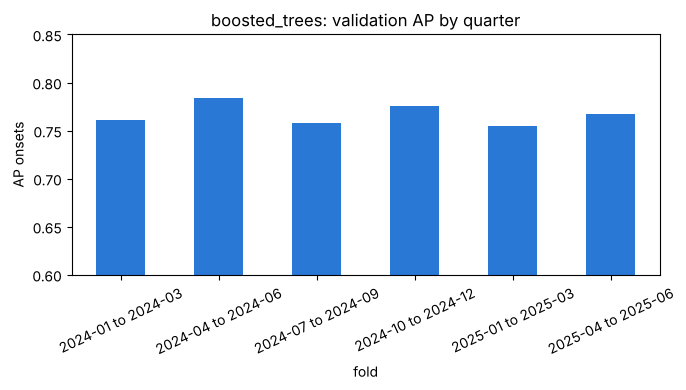

In [5]:
metric_columns = ["AP, onsets", "AP, all", "Brier", "caught ≥15 min", "false alarms / day", "wrong-alert hours / day",
                  "alerts right", "median lead (min)", "onsets"]

table = fold_results[metric_columns].copy()
table.loc["mean"] = fold_results[metric_columns].mean()
table.loc["std"] = fold_results[metric_columns].std()
display(table.round(4))
table.to_csv(RUN_DIR / "metric_summary.csv")

fig, ax = plt.subplots(figsize=(7, 4))
fold_results["AP, onsets"].plot.bar(ax=ax, color="#2a78d6")
ax.set(ylabel="AP onsets", title=f"{MODEL_NAME}: validation AP by quarter", ylim=(0.6, 0.85))
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

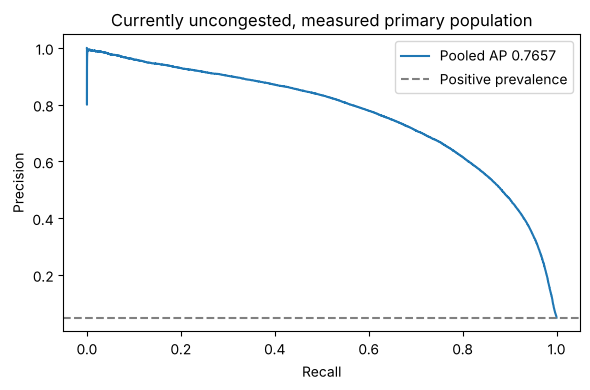

Mean per-fold AP: 0.7666
Pooled AP: 0.7657


In [6]:
primary = predictions["y_known"] & predictions["real"] & ~predictions["congested_now"]
primary_rows = predictions.loc[primary]
precision, recall, _ = precision_recall_curve(primary_rows["y"], primary_rows["probability"])
pooled_AP = average_precision_score(primary_rows["y"], primary_rows["probability"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall, precision, label=f"Pooled AP {pooled_AP:.4f}")
ax.axhline(primary_rows["y"].mean(), color="grey", linestyle="--", label="Positive prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Currently uncongested, measured primary population")
ax.legend()
fig.tight_layout()
plt.show()

print("Mean per-fold AP:", round(fold_results["AP, onsets"].mean(), 4))
print("Pooled AP:", round(pooled_AP, 4))

## 4. Catching jams versus false alarms

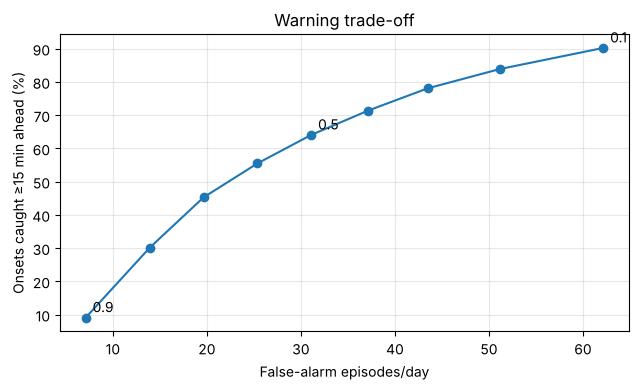

,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
threshold,,,,,,
0.1,0.902,62.155,18.486,0.756,30.0,9293
0.2,0.839,51.176,12.012,0.824,30.0,9293
0.3,0.781,43.488,8.769,0.863,30.0,9293
0.4,0.714,37.155,6.653,0.890,25.0,9293
0.5,0.640,31.083,5.039,0.913,25.0,9293
0.6,0.555,25.365,3.757,0.932,20.0,9293
0.7,0.453,19.640,2.644,0.949,20.0,9293
0.8,0.302,13.931,1.646,0.966,15.0,9293
0.9,0.091,7.107,0.677,0.984,10.0,9293


In [7]:
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)
tradeoff = pd.DataFrame([sf.alert_metrics(predictions, predictions["probability"].to_numpy(), t) for t in thresholds],
                        index=pd.Index(thresholds, name="threshold"))
tradeoff.to_csv(RUN_DIR / "tradeoff.csv")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tradeoff["false alarms / day"], tradeoff["caught ≥15 min"] * 100, marker="o")
for t in (0.1, 0.5, 0.9):
    ax.annotate(str(t), (tradeoff.loc[t, "false alarms / day"], tradeoff.loc[t, "caught ≥15 min"] * 100),
                xytext=(5, 4), textcoords="offset points")
ax.set(xlabel="False-alarm episodes/day", ylabel="Onsets caught ≥15 min ahead (%)", title="Warning trade-off")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
display(tradeoff.round(3))

## 5. Probability calibration

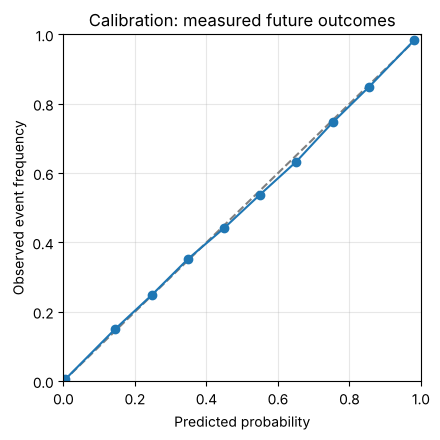

,predicted,actual,rows
probability,,,
"(-0.001, 0.1]",0.006,0.006,1415289
"(0.1, 0.2]",0.144,0.150,34258
"(0.2, 0.3]",0.246,0.248,19397
"(0.3, 0.4]",0.349,0.353,14718
"(0.4, 0.5]",0.449,0.441,12991
"(0.5, 0.6]",0.550,0.538,12495
"(0.6, 0.7]",0.651,0.633,13649
"(0.7, 0.8]",0.753,0.746,17709
"(0.8, 0.9]",0.855,0.849,28956


In [8]:
scored = predictions.loc[predictions["y_known"]]
bins = pd.cut(scored["probability"], np.linspace(0, 1, 11), include_lowest=True)
calibration = scored.groupby(bins, observed=True).agg(predicted=("probability", "mean"), actual=("y", "mean"), rows=("y", "size"))
calibration = calibration[calibration["rows"] >= 100]
calibration.to_csv(RUN_DIR / "calibration.csv")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.plot(calibration["predicted"], calibration["actual"], marker="o")
ax.set(xlabel="Predicted probability", ylabel="Observed event frequency", xlim=(0, 1), ylim=(0, 1),
       title="Calibration: measured future outcomes")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
display(calibration.round(3))

## 6. Station coverage

Predictions for stations without eligible outcomes don't count toward validated performance. This shows how many scored rows each station
contributes.

In [9]:
eligible = predictions["y_known"] & predictions["real"] & ~predictions["congested_now"]
coverage = (predictions.assign(eligible=eligible, positive=eligible & predictions["y"])
            .groupby("station")
            .agg(predictions=("probability", "size"), known_outcomes=("y_known", "sum"),
                 primary_rows=("eligible", "sum"), primary_positives=("positive", "sum")))
display(coverage)
print("Stations with primary scoring:", int(coverage["primary_rows"].gt(0).sum()), "/", len(coverage))

,predictions,known_outcomes,primary_rows,primary_positives
station,,,,
1205045,63000,0,0,0
1205071,63000,28244,27100,1952
1205088,63000,46171,25634,4509
1205135,63000,51741,44199,7483
1205152,63000,56478,56065,363
1205157,63000,4181,4170,36
1205165,63000,60046,58348,2857
1205168,63000,20016,15426,1573
1205175,63000,59970,42800,4559


Stations with primary scoring: 40 / 46


## 7. Save and team comparison

A full run writes `notebooks/results/boosted_trees_folds.csv` and `boosted_trees_manifest.json`, and replaces this model's row in
`notebooks/results/summary.csv`. Other models' rows are kept. Quick runs stay local. Commit the run folder's `validation_predictions.parquet` files and `manifest.json` (the folder's
`.gitignore` keeps everything else local).

In [10]:
if QUICK_RUN:
    print("Quick run: team results not saved")
else:
    summary = training.publish_team_results(TEAM_RESULTS, MODEL_NAME, fold_results, metric_columns, FEATURES, manifest)
    display(summary.set_index("model").round(4))
print("Completed run:", RUN_DIR.relative_to(PROJECT_DIR))

,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
model,,,,,,,,,
boosted_trees,2026-11-04,29,0.7666,0.0110,0.7552,0.0220,0.6395,31.0961,5.0443
transformer_shared_plus_agreed_features,2026-10-31,29,0.7625,0.0168,0.7317,0.0223,0.6633,30.4317,5.5437
random_forest_shared_29_features,2026-10-31,29,0.7495,0.0088,0.7384,0.0230,0.5258,30.0483,4.4619


Completed run: src/boosted_trees/results/boosted_trees_29_features_full_20261104_000723
